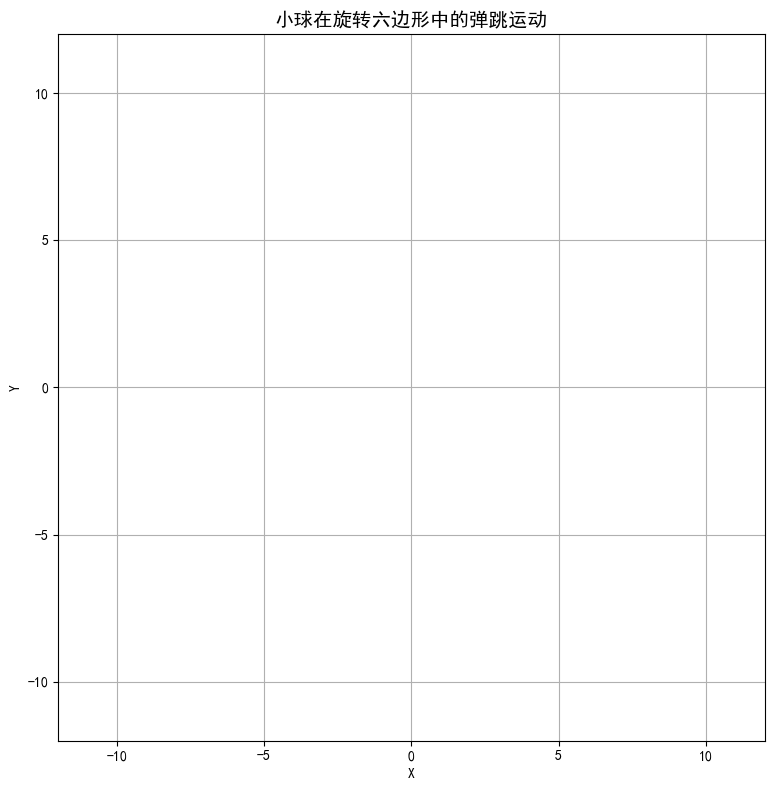

In [ ]:
import matplotlib.pyplot as plt
plt.rcParams['animation.embed_limit'] = 50
import plotly.graph_objects as go
import plotly.express as px
import numpy as np
import seaborn as sns
import pandas as pd
from matplotlib.animation import FuncAnimation


# 设置中文字体和负号显示
plt.rcParams['font.sans-serif'] = ['WenQuanYi Zen Hei', 'SimHei', 'Microsoft YaHei', 'DejaVu Sans']
plt.rcParams['axes.unicode_minus'] = False

# 参数设置
L = 10  # 环境大小（正六边形外接圆半径）
omega = 0.5  # 六边形旋转角速度 (rad/s)
g = 0.1  # 重力加速度
friction = 0.98  # 摩擦系数（小于1表示能量损失）
dt = 0.05  # 时间步长
num_steps = 1000  # 动画帧数

# 初始位置和速度
x, y = L * 0.5, L * 0.5
vx, vy = 0.3, -0.2

# 六边形顶点坐标（初始静止时）
n_sides = 6
theta = np.linspace(0, 2*np.pi, n_sides + 1)
hex_vertices_static = np.array([L * np.cos(theta), L * np.sin(theta)]).T

# 存储轨迹
trajectory_x, trajectory_y = [], []

# 创建图形和轴
fig, ax = plt.subplots(figsize=(8, 8))
ax.set_xlim(-L*1.2, L*1.2)
ax.set_ylim(-L*1.2, L*1.2)
ax.set_aspect('equal')
ax.grid(True)

# 绘制六边形轮廓（随时间旋转）
hex_line, = ax.plot([], [], 'b-', linewidth=2)
ball_point, = ax.plot([], [], 'ro', markersize=10)

# 初始化函数：清空图像
def init():
    hex_line.set_data([], [])
    ball_point.set_data([], [])
    return hex_line, ball_point

# 更新函数：每帧更新一次状态
def update(frame):
    global x, y, vx, vy

    # 当前旋转角度（随时间变化）
    angle_rot = omega * frame * dt

    # 计算当前旋转后的六边形顶点
    cos_a, sin_a = np.cos(angle_rot), np.sin(angle_rot)
    rotation_matrix = np.array([[cos_a, -sin_a], [sin_a, cos_a]])

    hex_vertices_rotated = np.dot(hex_vertices_static, rotation_matrix.T)

    # 更新球的位置和速度
    vx += g * dt * np.sin(angle_rot) * (-1)  # 受旋转影响的“有效”重力分量（简化模型）
    vy += g * dt * np.cos(angle_rot) * (-1)

    x += vx * dt
    y += vy * dt

    # 应用摩擦（减小速度）
    vx *= friction
    vy *= friction

    # 检测与六边形壁面的碰撞并反弹（简化处理：检查是否在多边形外部）
    def point_in_polygon(px, py, vertices):
        """判断点是否在多边形内部"""
        n = len(vertices)
        inside = False
        p1x, p1y = vertices[0]
        for i in range(1, n + 1):
            p2x, p2y = vertices[i % n]
            if py > min(p1y, p2y):
                if py <= max(p1y, p2y):
                    if px <= max(p1x, p2x):
                        if p1y != p2y:
                            xinters = (py - p1y) * (p2x - p1x) / (p2y - p1y) + p1x
                        if p1x == p2x or px <= xinters:
                            inside = not inside
            p1x, p1y = p2x, p2y
        return inside

    # 如果球在六边形外面，则进行反弹修正（模拟碰撞）
    if not point_in_polygon(x, y, hex_vertices_rotated):
        # 找到最近的边并计算法向量方向进行反射
        min_dist_to_edge = float('inf')
        normal_vector = None

        for i in range(n_sides):
            v1 = hex_vertices_rotated[i]
            v2 = hex_vertices_rotated[(i+1) % n_sides]
            edge_vec = v2 - v1
            edge_len_sq = np.dot(edge_vec, edge_vec)

            # 向量从v1指向球心
            to_ball_vec = np.array([x - v1[0], y - v1[1]])

            # 投影长度（沿边的方向）
            proj_length = np.dot(to_ball_vec, edge_vec) / edge_len_sq

            # 投影点在边上吗？
            if proj_length < 0:
                closest_point_on_edge = v1.copy()
            elif proj_length > 1:
                closest_point_on_edge = v2.copy()
            else:
                closest_point_on_edge = v1 + proj_length * edge_vec

            dist_to_edge_sq = np.sum((np.array([x,y]) - closest_point_on_edge)**2)

            if dist_to_edge_sq < min_dist_to_edge:
                min_dist_to_edge = dist_to_edge_sq
                normal_dir = (np.array([x,y]) - closest_point_on_edge) / (np.sqrt(dist_to_edge_sq)+1e-8)

                # 法线方向应垂直于边，且向外指（需调整符号）
                perp_vec = np.array([-edge_vec[1], edge_vec[0]]) / (np.linalg.norm(edge_vec)+1e-8)
                if np.dot(perp_vec, normal_dir) < 0:
                    normal_dir *= -1

                normal_vector = normal_dir

        if normal_vector is not None:
            # 反弹：v_new = v - 2(v·n)n （标准反射公式）
            dot_product = vx * normal_vector[0] + vy * normal_vector[1]
            vx -= 2 * dot_product * normal_vector[0]
            vy -= 2 * dot_product * normal_vector[1]

            # 将球移回边界内一点以避免穿透（微调位置）
            correction_factor = 0.9999999999999999999999999999999999   # 极小值防止无限循环
            x -= normal_vector[0] * np.sqrt(min_dist_to_edge) * correction_factor
            y -= normal_vector[1] * np.sqrt(min_dist_to_edge) * correction_factor

    # 添加当前位置到轨迹列表中
    trajectory_x.append(x)
    trajectory_y.append(y)

    # 更新绘图数据
    hex_line.set_data(hex_vertices_rotated[:, 0], hex_vertices_rotated[:, 1])
    ball_point.set_data([x], [y])

    return hex_line, ball_point

# 创建动画对象
ani = FuncAnimation(fig, update, frames=num_steps,
                     init_func=init, blit=True, interval=50)

plt.title("小球在旋转六边形中的弹跳运动", fontsize=14)
plt.xlabel("X")
plt.ylabel("Y")

# 显示动画（Jupyter环境支持）
plt.tight_layout()
plt.show()

In [8]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.animation as animation
from matplotlib.patches import Circle, RegularPolygon

# 设置中文字体和负号显示
plt.rcParams['font.sans-serif'] = ['WenQuanYi Zen Hei', 'SimHei', 'Microsoft YaHei', 'DejaVu Sans']
plt.rcParams['axes.unicode_minus'] = False
plt.rcParams['animation.embed_limit'] = 50

# 物理参数
HEXAGON_RADIUS = 5.0  # 六边形外接圆半径
BALL_RADIUS = 0.3     # 小球半径
GRAVITY = np.array([0.0, -9.8])  # 重力加速度
AIR_FRICTION = 0.995  # 空气阻力/摩擦系数 (每帧速度衰减)
RESTIUTION = 0.85     # 碰撞恢复系数
ANGULAR_VELOCITY = 1.5  # 六边形旋转角速度 (rad/s)

# 初始状态
ball_pos = np.array([0.0, 2.0])  # 小球初始位置
ball_vel = np.array([3.0, 0.0])  # 小球初始速度
hex_rotation = 0.0  # 六边形当前旋转角度

def get_hexagon_vertices(rotation_angle):
    """计算旋转后六边形的顶点坐标"""
    vertices = []
    for i in range(6):
        # 六边形每个顶点间隔60度 (π/3 弧度)
        angle = rotation_angle + i * np.pi / 3
        x = HEXAGON_RADIUS * np.cos(angle)
        y = HEXAGON_RADIUS * np.sin(angle)
        vertices.append([x, y])
    return np.array(vertices)

def point_to_line_distance(point, p1, p2):
    """计算点到线段的距离和最近点"""
    line_vec = p2 - p1
    point_vec = point - p1
    
    # 计算投影参数 t
    line_len_sq = np.dot(line_vec, line_vec)
    if line_len_sq < 1e-10:
        return np.linalg.norm(point - p1), p1
    
    t = np.dot(point_vec, line_vec) / line_len_sq
    t = np.clip(t, 0.0, 1.0)
    
    # 最近点
    closest = p1 + t * line_vec
    distance = np.linalg.norm(point - closest)
    
    return distance, closest

def check_wall_collision(ball_pos, ball_vel, ball_radius, vertices, dt):
    """检测并处理与所有墙壁的碰撞"""
    new_pos = ball_pos.copy()
    new_vel = ball_vel.copy()
    collision_occurred = False
    
    # 检查每个墙壁 (六边形有6条边)
    for i in range(6):
        p1 = vertices[i]
        p2 = vertices[(i + 1) % 6]
        
        # 墙壁法向量 (指向内部)
        wall_tangent = p2 - p1
        wall_normal = np.array([wall_tangent[1], -wall_tangent[0]])
        norm = np.linalg.norm(wall_normal)
        if norm < 1e-10:
            continue
        
        wall_normal = wall_normal / norm
        
        # 确保法向量指向内部 (朝向中心)
        center_dir = - (p1 + p2) / 2  # 指向中心的方向
        if np.dot(wall_normal, center_dir) < 0:
            wall_normal = -wall_normal
        
        # 计算小球到墙壁的距离
        dist, closest_point = point_to_line_distance(ball_pos, p1, p2)
        
        # 如果距离小于小球半径，发生碰撞
        if dist < ball_radius:
            # 将小球推出墙壁
            penetration = ball_radius - dist
            new_pos += wall_normal * penetration
            
            # 计算碰撞点处的墙壁速度 (由于旋转)
            # 在2D中，角速度引起的线速度: v = ω × r
            # 对于2D: ω 是标量，方向垂直于平面
            # v_wall = (-ω*y, ω*x)
            collision_point = closest_point
            wall_vel = np.array([
                -ANGULAR_VELOCITY * collision_point[1],
                ANGULAR_VELOCITY * collision_point[0]
            ])
            
            # 相对速度
            rel_vel = new_vel - wall_vel
            
            # 如果小球正在进入墙壁 (相对速度指向内部)
            if np.dot(rel_vel, wall_normal) < 0:
                # 反射速度向量
                # v_new = v - 2 * (v·n) * n
                normal_vel = np.dot(rel_vel, wall_normal)
                new_rel_vel = rel_vel - 2 * normal_vel * wall_normal
                
                # 应用恢复系数和添加墙壁速度
                new_vel = wall_vel + RESTIUTION * new_rel_vel
                collision_occurred = True
    
    return new_pos, new_vel, collision_occurred

def update_physics(ball_pos, ball_vel, vertices, dt):
    """更新物理状态"""
    # 1. 应用重力
    new_vel = ball_vel + GRAVITY * dt
    
    # 2. 应用空气阻力/摩擦
    new_vel *= AIR_FRICTION
    
    # 3. 更新位置
    new_pos = ball_pos + new_vel * dt
    
    # 4. 检测并处理碰撞
    new_pos, new_vel, collision = check_wall_collision(
        new_pos, new_vel, BALL_RADIUS, vertices, dt
    )
    
    return new_pos, new_vel

# 创建图形
fig, ax = plt.subplots(figsize=(8, 8))
ax.set_aspect('equal')
ax.set_xlim(-7, 7)
ax.set_ylim(-7, 7)
ax.axis('off')
ax.set_title('小球在旋转六边形中的弹跳', fontsize=14, pad=20)

# 创建图形元素
hexagon_patch = RegularPolygon(xy=(0, 0), numVertices=6, radius=HEXAGON_RADIUS, 
                               orientation=hex_rotation, 
                               facecolor='lightgray', 
                               edgecolor='black', 
                               linewidth=2)
ball_patch = Circle(ball_pos, BALL_RADIUS, facecolor='red', edgecolor='darkred')

ax.add_patch(hexagon_patch)
ax.add_patch(ball_patch)

def animate(frame):
    global ball_pos, ball_vel, hex_rotation
    
    dt = 1/60  # 60 FPS
    
    # 更新六边形旋转角度
    hex_rotation += ANGULAR_VELOCITY * dt
    vertices = get_hexagon_vertices(hex_rotation)
    
    # 更新物理
    ball_pos, ball_vel = update_physics(ball_pos, ball_vel, vertices, dt)
    
    # 更新图形
    # hexagon_patch.set_orientation(hex_rotation)
    hexagon_patch.orientation = hex_rotation
    ball_patch.center = ball_pos
    
    return hexagon_patch, ball_patch

# 创建动画
ani = animation.FuncAnimation(
    fig, animate, 
    frames=1000,  # 总帧数
    interval=16,  # 约60 FPS (16ms)
    blit=True
)

ani.save('bouncing_ball.gif', writer='pillow', fps=60)
print("动画已保存为bouncing_ball.gif")

# plt.title("小球在旋转六边形中的弹跳运动", fontsize=14)
# plt.xlabel("X")
# plt.ylabel("Y")

# # 显示动画（Jupyter环境支持）
# plt.tight_layout()
# plt.show()


# 在Jupyter中显示动画
from IPython.display import HTML
plt.close()  # 防止显示静态图
HTML(ani.to_jshtml())